# ChaCha20 auf dem CW-Lite (STM32F3): Test & erste Traces

Dieses Notebook testet die Firmware `firmware/mcu/simpleserial-chacha20`, also ChaCha20 in der **IETF-Variante** (RFC 8439: 96-Bit-Nonce, 32-Bit-Counter).

**Ablauf:**
1. Setup: Scope und Target verbinden
2. Firmware bauen und flashen
3. Referenz (pycryptodome) gegen die RFC-8439-Testvektoren prüfen
4. Target gegen die Referenz validieren
5. Trace-Länge bestimmen (passt der Block ins Sample-Fenster?)
6. Traces aufnehmen und speichern (fester Schlüssel, zufällige Nonce und zufälliger Counter, Grundlage für eine spätere CPA)

**SimpleSerial-Befehle der Firmware:**

| Befehl | Länge | Funktion |
|---|---|---|
| `'k'` | 32 B | Schlüssel setzen |
| `'n'` | 16 B | Counter (4 B, little endian) und Nonce (12 B) |
| `'p'` | 16 B | 16 B Klartext verschlüsseln, Antwort `'r'` mit 16 B |
| `'x'` | 0 B | Schlüssel, Nonce und Counter auf null setzen |

## 1. Setup

In [1]:
SCOPETYPE = 'OPENADC'
PLATFORM  = 'CWLITEARM'    #STM32
SS_VER    = 'SS_VER_1_1'

FW_DIR = "../../firmware/mcu/simpleserial-chacha20"

%run "../Setup_Scripts/Setup_Generic.ipynb"

INFO: Found ChipWhisperer😍
scope.gain.mode                          changed from low                       to high                     
scope.gain.gain                          changed from 0                         to 30                       
scope.gain.db                            changed from 5.5                       to 24.8359375               
scope.adc.basic_mode                     changed from low                       to rising_edge              
scope.adc.samples                        changed from 24445                     to 5000                     
scope.adc.trig_count                     changed from 9170053                   to 37087407                 
scope.clock.adc_src                      changed from clkgen_x1                 to clkgen_x4                
scope.clock.adc_freq                     changed from 0                         to 42264244                 
scope.clock.adc_rate                     changed from 0.0                       to 42264244.0        

## 2. Firmware bauen und flashen

In [2]:
%%bash -s "$FW_DIR"
cd "$1"
make -j

SS_VER set to SS_VER_1_1
SS_VER set to SS_VER_1_1
arm-none-eabi-gcc (Arm GNU Toolchain 15.3.Rel1 (Build arm-15.149)) 15.3.1 20260627
Copyright (C) 2025 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWLITEARM 
.
Welcome to another exciting ChipWhisperer target build!!
.
.
.
.
.
.
.
Compiling:
Compiling:
Compiling:
Compiling:
Compiling:
-en     .././simpleserial/simpleserial.c ...
-en     .././hal//stm32f3/stm32f3_hal.c ...
-en     .././hal//stm32f3/stm32f3_hal_lowlevel.c ...
-en     .././hal//stm32f3/stm32f3_sysmem.c ...
-en     .././hal/hal.c ...
Compiling:
Compiling:
-en     chacha20.c ...
.
-en     simpleserial-chacha20.c ...
Assembling: .././hal//stm32f3/stm32f3_startup.S
arm-none-eabi-gcc -c -mcpu=cortex-m4 -I. -x assembler-with-cpp -mthumb -mfloat-abi=soft -fmessage-length=0 -ffunction-sections -DF_CPU=7372800 -Wa,-gstabs,-adhlns=

/Applications/ArmGNUToolchain/15.3.rel1/arm-none-eabi/bin/../lib/gcc/arm-none-eabi/15.3.1/../../../../arm-none-eabi/bin/ld: warning: simpleserial-chacha20-CWLITEARM.elf has a LOAD segment with RWX permissions


Memory region         Used Size  Region Size  %age Used
             RAM:        1736 B        40 KB      4.24%
             ROM:        5344 B       256 KB      2.04%
-e Done!
.
.
.
.
.
Creating load file for Flash: simpleserial-chacha20-CWLITEARM.hex
Creating load file for Flash: simpleserial-chacha20-CWLITEARM.bin
arm-none-eabi-objcopy -O ihex -R .eeprom -R .fuse -R .lock -R .signature simpleserial-chacha20-CWLITEARM.elf simpleserial-chacha20-CWLITEARM.hex
arm-none-eabi-objcopy -O binary -R .eeprom -R .fuse -R .lock -R .signature simpleserial-chacha20-CWLITEARM.elf simpleserial-chacha20-CWLITEARM.bin
Creating Extended Listing: simpleserial-chacha20-CWLITEARM.lss
arm-none-eabi-objdump -h -S -z simpleserial-chacha20-CWLITEARM.elf > simpleserial-chacha20-CWLITEARM.lss
Creating load file for EEPROM: simpleserial-chacha20-CWLITEARM.eep
Creating Symbol Table: simpleserial-chacha20-CWLITEARM.sym
arm-none-eabi-objcopy -j .eeprom --set-section-flags=.eeprom="alloc,load" \
	--change-section-l

In [3]:
cw.program_target(scope, prog, "{}/simpleserial-chacha20-{}.hex".format(FW_DIR, PLATFORM))
reset_target(scope)
target.flush()

Detected known STMF32: STM32F302xB(C)/303xB(C)
Extended erase (0x44), this can take ten seconds or more
Attempting to program 5343 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 5343 bytes


## 3. Referenzimplementierungen prüfen

Es gibt zwei Referenzen:

- **`pycryptodome`**: unabhängige, etablierte Implementierung. Sie wählt die Variante anhand der Nonce-Länge, 12 Byte entsprechen IETF/RFC 8439. Falls der Import fehlschlägt, einmal `%pip install pycryptodome` ausführen und den Kernel neu starten.
- **`chacha20_sim.py`**: 1:1-Python-Nachbau der Firmware-Datei `chacha20.c` mit gleichen Funktionen, Schleifen und Reihenfolge. Damit lassen sich später auch Zwischenwerte der Runden für die CPA berechnen.

Beide werden gegen den RFC-8439-Testvektor und gegeneinander geprüft.

In [1]:
import os
import numpy as np
from Crypto.Cipher import ChaCha20
from chacha20_sim import ChaCha20XOR as sim_ChaCha20XOR

def chacha_ref(key, ctr, nonce, pt):
    # ChaCha20 (IETF) Referenz (pycryptodome): Keystream ab Block 'ctr' XOR pt
    assert len(key) == 32 and len(nonce) == 12
    c = ChaCha20.new(key=bytes(key), nonce=bytes(nonce))
    c.seek(64 * ctr)
    return c.encrypt(bytes(pt))

def rand_ctr():
    # Zufälliger 32-Bit-Counter. 0xFFFFFFFF wird ausgelassen, weil pycryptodome
    # (IETF) für den letzten Block keinen seek() erlaubt; Firmware und
    # Simulation können ihn, das ist nur eine Einschränkung der Referenz.
    while True:
        ctr = int.from_bytes(os.urandom(4), 'little')
        if ctr != 0xFFFFFFFF:
            return ctr

def chacha_sim(key, ctr, nonce, pt):
    # ChaCha20 Simulation der Firmware (chacha20_sim.py), Aufruf wie in C
    out = [0] * len(pt)
    sim_ChaCha20XOR(key, ctr, nonce, pt, out, len(pt))
    return bytes(out)

# RFC 8439, Abschnitt 2.4.2 (Testvektor für die Verschlüsselung)
RFC_KEY   = bytes(range(32))
RFC_NONCE = bytes.fromhex("000000000000004a00000000")
RFC_CTR   = 1
RFC_PT    = b"Ladies and Gentlemen of the class of '99: If I could offer you only one tip for the future, sunscreen would be it."
RFC_CT    = bytes.fromhex(
    "6e2e359a2568f98041ba0728dd0d6981e97e7aec1d4360c20a27afccfd9fae0b"
    "f91b65c5524733ab8f593dabcd62b3571639d624e65152ab8f530c359f0861d8")  # erste 64 B

assert chacha_ref(RFC_KEY, RFC_CTR, RFC_NONCE, RFC_PT)[:64] == RFC_CT
print("pycryptodome stimmt mit RFC 8439 überein ✔")
assert chacha_sim(RFC_KEY, RFC_CTR, RFC_NONCE, RFC_PT)[:64] == RFC_CT
print("Simulation   stimmt mit RFC 8439 überein ✔")

# Simulation vs. pycryptodome mit Zufallsvektoren
N_CROSS = 100
for i in range(N_CROSS):
    key, nonce = os.urandom(32), os.urandom(12)
    ctr = rand_ctr()
    pt  = os.urandom(16)
    assert chacha_sim(key, ctr, nonce, pt) == chacha_ref(key, ctr, nonce, pt), f"Mismatch bei Vektor {i}"
print(f"Simulation   stimmt bei {N_CROSS} Zufallsvektoren mit pycryptodome überein ✔")

pycryptodome stimmt mit RFC 8439 überein ✔
Simulation   stimmt mit RFC 8439 überein ✔
Simulation   stimmt bei 100 Zufallsvektoren mit pycryptodome überein ✔


## 4. Target validieren

In [ ]:
def target_encrypt(key, ctr, nonce, pt):
    # Setzt Key/Counter/Nonce auf dem Target und verschlüsselt 16 Byte
    target.simpleserial_write('k', bytearray(key))
    if target.simpleserial_wait_ack() is None:
        raise IOError("kein ACK auf 'k'")
    target.simpleserial_write('n', bytearray(ctr.to_bytes(4, 'little') + bytes(nonce)))
    if target.simpleserial_wait_ack() is None:
        raise IOError("kein ACK auf 'n'")
    target.simpleserial_write('p', bytearray(pt))
    ct = target.simpleserial_read('r', 16)
    if ct is None:
        raise IOError("keine Antwort auf 'p'")
    return bytes(ct)

# 1) RFC-Testvektor (die ersten 16 Byte)
ct = target_encrypt(RFC_KEY, RFC_CTR, RFC_NONCE, RFC_PT[:16])
print("RFC  target:", ct.hex())
print("RFC  ref   :", RFC_CT[:16].hex())
print("RFC  sim   :", chacha_sim(RFC_KEY, RFC_CTR, RFC_NONCE, RFC_PT[:16]).hex())
assert ct == RFC_CT[:16], "Target liefert beim RFC-Vektor ein falsches Ergebnis!"
assert ct == chacha_sim(RFC_KEY, RFC_CTR, RFC_NONCE, RFC_PT[:16]), "Target weicht beim RFC-Vektor von der Simulation ab!"

# 2) Zufallsvektoren: Target vs. pycryptodome und vs. Simulation
N_VALIDATE = 20
for i in range(N_VALIDATE):
    key, nonce, pt = os.urandom(32), os.urandom(12), os.urandom(16)
    ctr = rand_ctr()
    ct  = target_encrypt(key, ctr, nonce, pt)
    assert ct == chacha_ref(key, ctr, nonce, pt), f"Target != pycryptodome bei Vektor {i}"
    assert ct == chacha_sim(key, ctr, nonce, pt), f"Target != Simulation bei Vektor {i}"

print(f"Target stimmt bei RFC-Vektor + {N_VALIDATE} Zufallsvektoren mit pycryptodome und Simulation überein ✔")

## 5. Trace-Länge bestimmen

`scope.adc.trig_count` zählt, wie viele ADC-Samples der Trigger high war, also wie lange `ChaCha20XOR()` läuft. Der CW-Lite kann maximal etwa 24 400 Samples pro Trace speichern.

In [6]:
key, nonce, pt = os.urandom(32), os.urandom(12), os.urandom(16)
ctr = 0
target.simpleserial_write('k', bytearray(key));  target.simpleserial_wait_ack()
target.simpleserial_write('n', bytearray(ctr.to_bytes(4, 'little') + nonce));  target.simpleserial_wait_ack()

scope.adc.samples = 24400
scope.arm()
target.simpleserial_write('p', bytearray(pt))
if scope.capture():
    print("Timeout!")
target.simpleserial_read('r', 16)

trig_samples = scope.adc.trig_count
print("Trigger high für     :", trig_samples, "Samples")
print("ADC-Takt / Target-Takt:", scope.clock.adc_src)
print("Max. Samples (CW-Lite):", 24400)
if trig_samples > 24400:
    print("→ Der ganze Block passt nicht ins Fenster: scope.adc.offset nutzen oder nur die ersten Runden aufnehmen.")
else:
    print("→ Der ganze Block passt ins Fenster.")

Trigger high für     : 24280 Samples
ADC-Takt / Target-Takt: clkgen_x4
Max. Samples (CW-Lite): 24400
→ Der ganze Block passt ins Fenster.


Ein erster Trace zur Orientierung. Die 10 Doppelrunden sollten als sich wiederholendes Muster erkennbar sein:

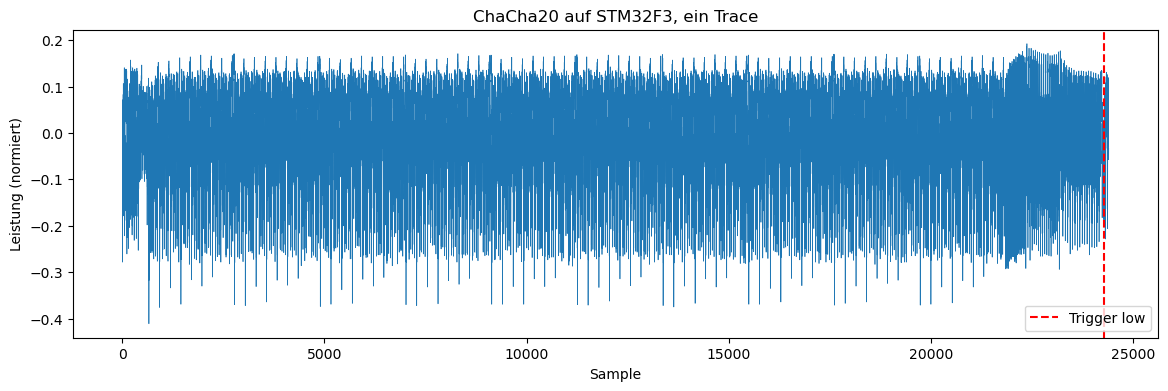

In [7]:
import matplotlib.pyplot as plt

trace = scope.get_last_trace()
plt.figure(figsize=(14, 4))
plt.plot(trace, lw=0.5)
plt.axvline(min(trig_samples, len(trace)), color='r', ls='--', label='Trigger low')
plt.xlabel("Sample"); plt.ylabel("Leistung (normiert)")
plt.title("ChaCha20 auf STM32F3, ein Trace")
plt.legend(); plt.show()

## 6. Traces aufnehmen

Fester (geheimer) Schlüssel, für jeden Trace zufälliger Counter und zufällige Nonce. Das entspricht dem Angreifermodell für eine CPA auf die ersten Quarterrounds: Die Wörter 12–15 sind bekannt und variieren. Jede Antwort wird gegen pycryptodome **und** gegen die Simulation geprüft. Nur Traces mit korrekter Antwort werden gespeichert.

In [ ]:
from tqdm.notebook import trange

N       = 1000
SAMPLES = 5000        # nach Abschnitt 5 anpassen (max. 24400)
OFFSET  = 0           # Samples nach dem Trigger überspringen

scope.adc.samples = SAMPLES
scope.adc.offset  = OFFSET

key = os.urandom(32)  # fester Schlüssel: das Ziel der späteren CPA
target.simpleserial_write('k', bytearray(key)); target.simpleserial_wait_ack()

traces, ctrnonce_in, pt_in, ct_out = [], [], [], []
errors = 0          # Timeouts / keine Antwort
mismatch_ref = 0    # Antwort != pycryptodome
mismatch_sim = 0    # Antwort != Simulation

for i in trange(N, desc="Capturing traces"):
    nonce = os.urandom(12)
    ctr   = rand_ctr()
    pt    = os.urandom(16)

    target.simpleserial_write('n', bytearray(ctr.to_bytes(4, 'little') + nonce))
    target.simpleserial_wait_ack()

    scope.arm()
    target.simpleserial_write('p', bytearray(pt))
    if scope.capture():
        print("Target timed out!"); errors += 1
        continue
    ct = target.simpleserial_read('r', 16)
    if ct is None:
        errors += 1
        continue
    ok_ref = bytes(ct) == chacha_ref(key, ctr, nonce, pt)
    ok_sim = bytes(ct) == chacha_sim(key, ctr, nonce, pt)
    mismatch_ref += not ok_ref
    mismatch_sim += not ok_sim
    if not (ok_ref and ok_sim):
        continue

    traces.append(scope.get_last_trace())
    ctrnonce_in.append(np.frombuffer(ctr.to_bytes(4, 'little') + nonce, dtype=np.uint8))
    pt_in.append(np.frombuffer(pt, dtype=np.uint8))
    ct_out.append(np.frombuffer(bytes(ct), dtype=np.uint8))

traces      = np.array(traces)
ctrnonce_in = np.array(ctrnonce_in)
pt_in       = np.array(pt_in)
ct_out      = np.array(ct_out)
print(f"{len(traces)} gültige Traces, {errors} Timeouts, "
      f"{mismatch_ref} Abweichungen zu pycryptodome, {mismatch_sim} Abweichungen zur Simulation")

In [9]:
np.savez("chacha20_traces.npz",
         traces=traces, ctrnonce=ctrnonce_in, pt=pt_in, ct=ct_out,
         key=np.frombuffer(key, dtype=np.uint8))
print("gespeichert: chacha20_traces.npz")

gespeichert: chacha20_traces.npz


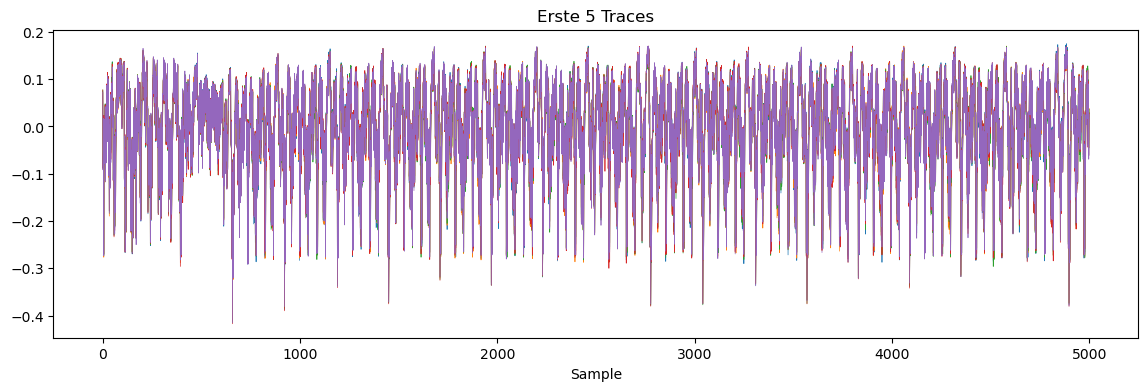

In [10]:
plt.figure(figsize=(14, 4))
for t in traces[:5]:
    plt.plot(t, lw=0.5)
plt.xlabel("Sample"); plt.title("Erste 5 Traces")
plt.show()

## Hardware trennen

In [11]:
scope.dis()
target.dis()